In [1]:
! pip install -r ../requirements.txt
import sys
sys.path.append("..")

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import awkward as ak
import matplotlib.pyplot as plt
import numpy as np
import uproot

import lehad

In [3]:
# The cuts are the selection: Don't include any events failing these criteria.
# Under the hood, I think this is performing the boolean comparison operations numpy style which is why the syntax is a little restrictive.
# (Yes, this needs to use bitwise & not logical and.)
# This would need to be a nice place to apply a "preselection" where we throw out events
#   we definitely won't ever care about.
CUTS = """
(Enu < 4.5) & \
(flagCC) \
"""

In [4]:
# G18, G21, AR23, GiBUU

generators = {"G18": lehad.GeneratorType.G18, "G21": lehad.GeneratorType.G21, "AR23": lehad.GeneratorType.AR23, "GiBUU": lehad.GeneratorType.GiBUU}
selected_generators = ["G18", "G21", "AR23", "GiBUU"]

print("Querying filepaths...")
filepaths = {i: lehad.get_generator_filepaths(generators[i],lehad.BeamType.FHC,lehad.NeutrinoType.Numu) for i in selected_generators}
for i in filepaths:
    print(f"Got: {filepaths}")

indices = {"G18": [0, 1], "G21": [0, 1], "AR23": [0, 1], "GiBUU": [0, 1]}
# indices = {
#     "G18": range(len(filepaths["G18"])),
#     "G21": range(len(filepaths["G21"])),
#     "AR23": range(len(filepaths["AR23"])),
#     "GiBUU": range(len(filepaths["GiBUU"]))
# }

input_paths = {j: [filepaths[j][i] for i in indices[j]] for j in selected_generators}

n_files = {i: len(input_paths[i]) for i in selected_generators}

enabled_branches_list = {i: [] for i in selected_generators}

for generator in selected_generators:
    for input_path in input_paths[generator]:
        print(f'Opening input {input_path}...')
        # Uproot works with an input file handle.
        with uproot.open(input_path) as infile:
            # The "tree" is an object inside the input file - it's a columnar dataset.
            tree = infile['generator_data']
            # We can investigate the tree before reading objects like so:
            print(tree.typenames())
            
            # Access the tree by asking for one (or multiple) of its branches.
            # This is a dict { branch name -> branch }
            #   where "branch" is some structure indexed by event. It can be a list of scalars, a list of four-vectors, etc.
            enabled_branches_list[generator].append(tree.arrays(
                ['Enu','n_FS_Protons', 'n_FS_Neutrons', 'n_FS_Muons', 'n_FS_PiPs', 'n_FS_PiMs', 'n_FS_Pi0s', 'FS_Protons', 'FS_Neutrons', 'FS_Muons', 'EventWeight', 'GenScaleFactor'],
            CUTS))

enabled_branches = {i: ak.concatenate(enabled_branches_list[i]) for i in selected_generators}
for i in enabled_branches.values():
    print(i.type)

Querying filepaths...
Got: {'G18': [PosixPath('/cluster/tufts/lblnu/nova/data/generators/v3.00.06_G18_10j_00_000/FHCDeriveFlux50MeVwidth_ppfx/numu_only/GENIE:G18_10j_00_000.10.FHC.1m.numu.convenient_output.root'), PosixPath('/cluster/tufts/lblnu/nova/data/generators/v3.00.06_G18_10j_00_000/FHCDeriveFlux50MeVwidth_ppfx/numu_only/GENIE:G18_10j_00_000.11.FHC.1m.numu.convenient_output.root'), PosixPath('/cluster/tufts/lblnu/nova/data/generators/v3.00.06_G18_10j_00_000/FHCDeriveFlux50MeVwidth_ppfx/numu_only/GENIE:G18_10j_00_000.2.FHC.1m.numu.convenient_output.root'), PosixPath('/cluster/tufts/lblnu/nova/data/generators/v3.00.06_G18_10j_00_000/FHCDeriveFlux50MeVwidth_ppfx/numu_only/GENIE:G18_10j_00_000.3.FHC.1m.numu.convenient_output.root'), PosixPath('/cluster/tufts/lblnu/nova/data/generators/v3.00.06_G18_10j_00_000/FHCDeriveFlux50MeVwidth_ppfx/numu_only/GENIE:G18_10j_00_000.4.FHC.1m.numu.convenient_output.root'), PosixPath('/cluster/tufts/lblnu/nova/data/generators/v3.00.06_G18_10j_00_000/

In [10]:
# Compute the weights per event with this prescription.
print('Computing weights...')
weights = {i: enabled_branches[i]['EventWeight']*enabled_branches[i]['GenScaleFactor']/n_files[i] for i in selected_generators}

# print('Printing...')
# print(enabled_branches)
# print('Enu:')
# print(enabled_branches['Enu'])

# print('n_FS_Protons:') # Expect a list of integers.
# print(enabled_branches['n_FS_Protons'])
# print('FS_Protons:') # Expect a list of lists of four-vectors.
# # First dereference by event index then dereference by FS proton index for this event.
# print(enabled_branches['FS_Protons'])

# print('n_FS_Neutrons:') # Expect a list of integers.
# print(enabled_branches['n_FS_Neutrons'])
# print('FS_Neutrons:') # Expect a list of lists of four-vectors.
# # First dereference by event index then dereference by FS proton index for this event.
# print(enabled_branches['FS_Neutrons'])

# print('n_FS_Muons:') # Expect a list of integers.
# print(enabled_branches['n_FS_Muons'])
# print('FS_Muons:') # Expect a list of lists of four-vectors.
# # First dereference by event index then dereference by FS proton index for this event.
# print(enabled_branches['FS_Muons'])

# print('FS_Protons with no pions:')
# # It's also legal to apply cuts at this stage like so: (elements of the logical expression do need to be in parantheses.)
# n_FS_PiPs = enabled_branches['n_FS_PiPs']
# n_FS_PiMs = enabled_branches['n_FS_PiMs']
# n_FS_Pi0s = enabled_branches['n_FS_Pi0s']
# print(enabled_branches['FS_Protons'][(n_FS_PiPs == 0) & (n_FS_PiMs == 0) & (n_FS_Pi0s == 0)])
# print('EventWeight:') # Expect a list of scalars.
# print(enabled_branches['EventWeight'])
# print('GenScaleFactor:') # Expect a list of scalars.
# print(enabled_branches['GenScaleFactor'])

# # We'll often want to interpret functions of the raw four-vectors.
# # Use python columnar manipulation to get proton energies.
# print('Proton energies:') # (The first element of a four-vector is its energy.)
# print(enabled_branches['FS_Protons'][:,:,0])
# Use a function to compute an interesting kinematic quantity.
proton_ke_sums = {i: lehad.proton_ke_sum(enabled_branches[i]) for i in selected_generators}
# print('Proton kinetic energies:')
# print(proton_ke_sums)

Computing weights...


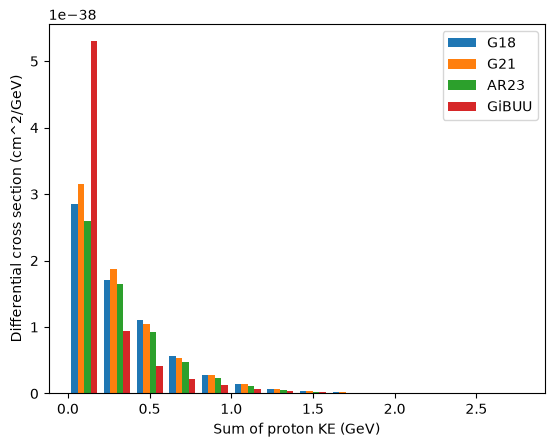

In [11]:
# Sum of Proton KE plot:
fix, ax = plt.subplots()
data = [proton_ke_sums[i] for i in selected_generators]
_, bins, patches = plt.hist(data, np.arange(0,3.0,0.2), weights=[weights[i]/0.2 for i in selected_generators], label = selected_generators)
ax.set_xlabel("Sum of proton KE (GeV)")
ax.set_ylabel("Differential cross section (cm^2/GeV)")
ax.legend()
plt.show()
plt.close()

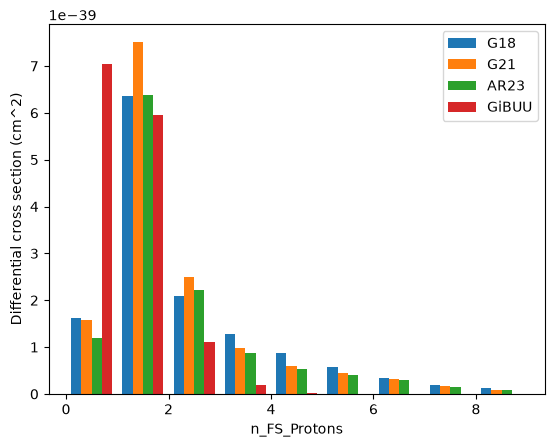

In [12]:
# N. of Protons Plot:
fix, ax = plt.subplots()
data = [enabled_branches[i]['n_FS_Protons'] for i in selected_generators]
_, bins, patches = plt.hist(data, np.arange(0,10.0,1), weights=[weights[i]/1 for i in selected_generators], label = selected_generators)
ax.set_xlabel("n_FS_Protons")
ax.set_ylabel("Differential cross section (cm^2)")
ax.legend()
plt.show()
plt.close()

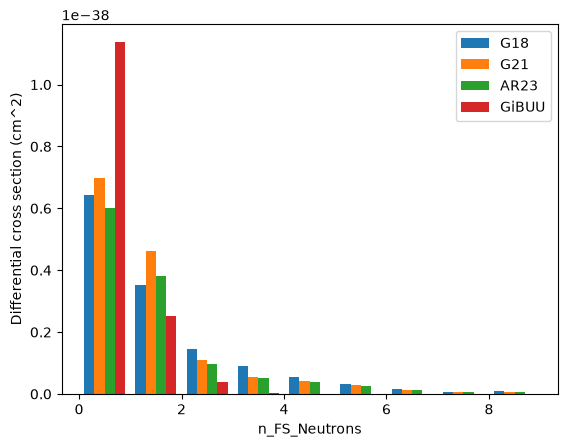

In [13]:
# N. of Neutrons Plot:
fix, ax = plt.subplots()
data = [enabled_branches[i]['n_FS_Neutrons'] for i in selected_generators]
_, bins, patches = plt.hist(data, np.arange(0,10.0,1), weights=[weights[i]/1 for i in selected_generators], label = selected_generators)
ax.set_xlabel("n_FS_Neutrons")
ax.set_ylabel("Differential cross section (cm^2)")
ax.legend()
plt.show()
plt.close()

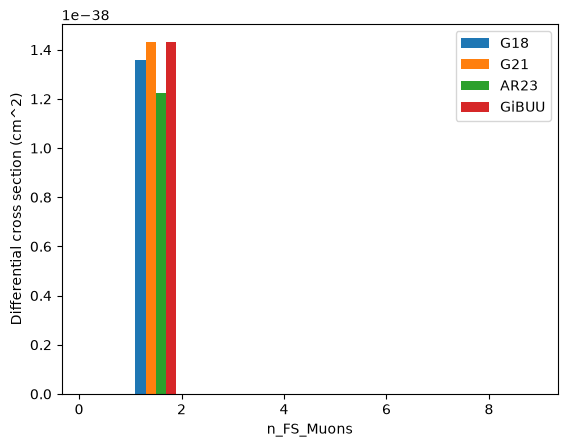

In [14]:
# N. of Muons Plot:
fix, ax = plt.subplots()
data = [enabled_branches[i]['n_FS_Muons'] for i in selected_generators]
_, bins, patches = plt.hist(data, np.arange(0,10.0,1), weights=[weights[i]/1 for i in selected_generators], label = selected_generators)
ax.set_xlabel("n_FS_Muons")
ax.set_ylabel("Differential cross section (cm^2)")
ax.legend()
plt.show()
plt.close()